# EMQA_L6_cheap_hours

**Share of Romanian solar energy sold in the cheapest hours: intervals of each calendar year ranked by day-ahead price, cumulative % of time (duration-weighted) against cumulative % of solar energy, for 2019, 2023, 2025 and 2026 (to 2026-10-31). Prints the share of solar output sold in the cheapest 10% of hours and at prices <= 0.**

Energy Markets Quantitative Analysis (EMQA), Lecture 6 · Daniel Traian Pele, Bucharest University of Economic Studies

[Open in Colab](https://colab.research.google.com/github/danpele/EMQA/blob/main/Quantlets/L6/EMQA_L6_cheap_hours/EMQA_L6_cheap_hours.ipynb)

In [1]:
import os
# course data: the local copy of the repository if there is one, else the public repository on GitHub
_LOCAL = os.path.join('..', '..', '..', 'data', 'clean')
DATA = _LOCAL + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/EMQA/main/data/clean/'
REPO = os.path.join('..', '..', '..') + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/EMQA/main/'

## Setup: chart style and data period

In [2]:
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings('ignore')

# course chart style: transparent background, no grid, legend at the bottom outside the axes, fixed colour per zone
PAL = {'RO': '#2a78d6', 'DE_LU': '#eb6834', 'HU': '#1baf7a', 'BG': '#eda100',
       'c5': '#e87ba4', 'c6': '#008300', 'c7': '#6250d6', 'c8': '#e34948'}
ZONE_LS = {'RO': '-', 'BG': '--', 'HU': '-.', 'DE_LU': ':'}
ZN = {'RO': 'Romania', 'BG': 'Bulgaria', 'HU': 'Hungary', 'DE_LU': 'Germany-Lux.'}
INK = '#222222'
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': INK, 'axes.labelcolor': INK, 'xtick.color': INK, 'ytick.color': INK,
    'text.color': INK, 'font.size': 11, 'axes.titlesize': 11.5, 'axes.labelsize': 11,
    'legend.fontsize': 10.5, 'legend.frameon': False, 'lines.linewidth': 1.4, 'font.family': 'DejaVu Sans'})


def legend_bottom(fig, ncol=4):
    """One legend for the whole figure, centred under the axes, outside the plotting area."""
    handles, labels = [], []
    for ax in fig.axes:
        for h, l in zip(*ax.get_legend_handles_labels()):
            if l not in labels:
                handles.append(h)
                labels.append(l)
    fig.legend(handles, labels, loc='lower center', ncol=ncol, bbox_to_anchor=(0.5, 0.0), frameon=False,
               handlelength=2.0, columnspacing=1.2)


def fl(x, k=4):
    """Rounding used for the numbers of the slides."""
    return None if x is None or np.isnan(float(x)) else round(float(x), k)


def show_numbers(d):
    for k, v in d.items():
        print(f'{k:<34} {v}')

Sort the intervals of a year by price; x = cumulative share of time (interval lengths), y = cumulative share of solar energy. A curve above the diagonal means solar is concentrated in cheap hours.

In [3]:
TZ = 'Europe/Brussels'                     # delivery days in CET/CEST
END = pd.Timestamp('2026-10-31')               # cut-off of Lecture 6 = last complete month of the data
END_X = (END + pd.Timedelta(days=1)).tz_localize(TZ)
Y = END.year
YEARS = list(range(2019, Y + 1))
MON_EN = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
YTD = f'* {Y} = Jan-{MON_EN[END.month - 1]}'
LTM0 = pd.Timestamp('2025-11-01').tz_localize(TZ)    # first day of the last 12 months
MTU15 = pd.Timestamp('2025-10-01').tz_localize(TZ)   # 15-min market time unit from 1 Oct 2025

In [4]:
# day-ahead prices, EUR/MWh: hourly to 30 Sep 2025, 15-min from 1 Oct 2025 (SDAC); index in CET/CEST
PX = pd.read_csv(DATA + 'power_da_prices_native_utc.csv', parse_dates=['timestamp_utc']).set_index('timestamp_utc')
PX.index = PX.index.tz_convert(TZ)
PX['dur'] = PX['mtu_minutes'] / 60.0          # interval length in hours
PX = PX[PX.index < END_X]
LOC_YEAR = PX.index.year
print('prices:', PX.index.min(), 'to', PX.index.max(), '|', (PX['mtu_minutes'] == 15).sum(), '15-min intervals')

prices: 2015-01-01 01:00:00+01:00 to 2026-10-31 23:45:00+01:00 | 38020 15-min intervals


In [5]:
def hfloor(idx):
    """Start of the clock hour, computed in UTC (no ambiguity on the autumn DST day)."""
    return idx.tz_convert('UTC').floor('1h').tz_convert(TZ)


def load_gen(c):
    """Generation and load of country c (ro, bg, hu), MW, native resolution, CET/CEST index."""
    g = pd.read_csv(DATA + f'generation_{c}_mw_native_utc.csv', parse_dates=['timestamp_utc']).set_index('timestamp_utc')
    g.index = g.index.tz_convert(TZ)
    return g


def on_price_grid(g):
    """Generation columns on the price grid: hourly mean for hourly prices; 15-min value for 15-min prices
    (the hourly value is repeated when the source is hourly, as for Bulgaria)."""
    gg = g.drop(columns=['mtu_minutes']).copy()
    out = gg.resample('1h').mean().reindex(hfloor(PX.index)).set_axis(PX.index)
    q15 = PX['mtu_minutes'] == 15
    if (g['mtu_minutes'] == 15).loc[g.index >= MTU15].all():
        out.loc[q15] = gg.resample('15min').mean().reindex(PX.index[q15]).values
    return out


GN = {c.upper(): load_gen(c) for c in ('ro',)}
GR = {z: on_price_grid(GN[z]) for z in GN}
print({z: (str(g.index.min())[:10], str(g.index.max())[:10]) for z, g in GN.items()})

{'RO': ('2018-12-30', '2026-11-04')}


In [6]:
ro = GR['RO']
LOR, CHEAP = {}, {}
for y in (2019, 2023, Y - 1, Y):
    m = (LOC_YEAR == y) & PX['RO'].notna().values & ro['solar'].notna().values
    p_, g_, w_ = PX['RO'][m].values, ro['solar'][m].values, PX['dur'][m].values
    o = np.argsort(p_, kind='stable')
    tsh = np.cumsum(w_[o]) / w_.sum()
    esh = np.cumsum((g_ * w_)[o]) / (g_ * w_).sum()
    LOR[y] = (tsh, esh)
    k10 = np.searchsorted(tsh, 0.10)
    CHEAP[y] = {'e_in_cheap10': fl(esh[k10] * 100, 1), 'e_le0': fl((g_ * w_)[p_ <= 0].sum() / (g_ * w_).sum() * 100, 1)}
show_numbers({'cheap.2019.e_in_cheap10': CHEAP[2019]['e_in_cheap10'], f'cheap.{Y - 1}.e_in_cheap10': CHEAP[Y - 1]['e_in_cheap10'],
              f'cheap.{Y - 1}.e_le0': CHEAP[Y - 1]['e_le0'], f'cheap.{Y}.e_in_cheap10': CHEAP[Y]['e_in_cheap10']})

cheap.2019.e_in_cheap10            7.6
cheap.2025.e_in_cheap10            32.1
cheap.2025.e_le0                   9.6
cheap.2026.e_in_cheap10            23.4


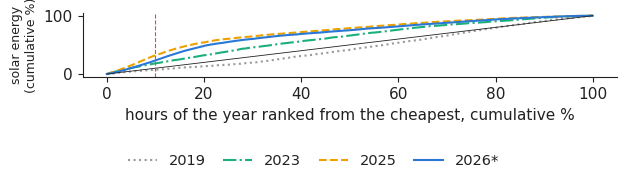

In [7]:
fig, ax = plt.subplots(figsize=(6.4, 1.85))
for y, col, ls in ((2019, '#9a9a9a', ':'), (2023, PAL['HU'], '-.'), (Y - 1, PAL['BG'], '--'), (Y, PAL['RO'], '-')):
    tsh, esh = LOR[y]
    ax.plot(tsh * 100, esh * 100, color=col, ls=ls, lw=1.5, label=str(y) + ('*' if y == Y else ''))
ax.plot([0, 100], [0, 100], color=INK, lw=0.6)
ax.axvline(10, color=PAL['c8'], lw=0.8, ls='--')
ax.set_xlabel('hours of the year ranked from the cheapest, cumulative %')
ax.set_ylabel('solar energy\n(cumulative %)', fontsize=9)
legend_bottom(fig, ncol=4)
fig.tight_layout(rect=(0, 0.23, 1, 1))
plt.savefig('cheap_hours.png', dpi=150, bbox_inches='tight', transparent=True)
plt.show()